# Probabilité d'acceptation dans la méthode des rejets

$p_k=6/(\pi^2 k^2)$ et $q_k=1/(k(k+1))$.

$ \frac{p_k}{q_k} = \frac{\dfrac{6}{\pi^2k^2}} {\dfrac1{k(k+1)}} = \frac{6}{\pi^2}\frac{k+1}{k}. $

$\frac{k+1}{k} = 1+\frac1k. $ Cette quantité est décroissante en $k$ et atteint son maximum pour $k=1$ : $ \sup_{k\geq 1}\frac{k+1}{k}=2. $

$c= \sup_{k\geq1}\frac{p_k}{q_k} = \frac{6}{\pi^2}\times 2 = \frac{12}{\pi^2}.$

 On obtient donc $ \boxed{ c=\frac{12}{\pi^2} } $

L'algorithme de rejet s'écrit :
- Simuler $Y\sim q$. \item Simuler $U\sim\mathcal U(0,1)$.
-  Accepter $Y$ si $ U\leq \frac{p_Y}{c\,q_Y}. $
-   Sinon recommencer. \end{enumerate}

La quantité $ \alpha(k) = \frac{p_k}{c\,q_k} $ est appelée \textbf{probabilité d'acceptation conditionnelle} associée à la valeur proposée $k$.

$\boxed{ \alpha(k)=\frac{k+1}{2k} }.$

Les petites valeurs de $k$ sont donc acceptées avec une probabilité très élevée.

La probabilité globale d'accepter une proposition vaut $ P(\text{acceptation}) = \sum_{k\geq1} q_k\,\alpha(k). $

$ P(\text{acceptation}) = \sum_{k\geq1} q_k \frac{p_k}{c\,q_k} = \frac1c \sum_{k\geq1} p_k=\frac1c = \frac{\pi^2}{12}\simeq 0.822467. $

Ainsi, pour obtenir $100\,000$ réalisations de la loi zêta, il faut en moyenne $ \frac{100000}{0.822467} \simeq 121\,585 $

propositions seulement, ce qui montre l'efficacité de la loi instrumentale $q_k=\frac1{k(k+1)}.$

# Simulation de la loi zêta $a=2$ par la méthode des rejets

$p_k=6/(\pi^2 k^2)$ et $q_k=1/(k(k+1))$.

## Rappel théorique

$c=12/\pi^2$ et la probabilité d'acceptation vaut $(k+1)/(2k)$.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

c=12/pi**2
print("c=",c)
print("Taux théorique=",pi**2/12)

c= 1.2158542037080533
Taux théorique= 0.8224670334241132


In [14]:
def pareto_discrete(n):
    u=np.random.rand(n)
    return np.floor(1/u).astype(int)

In [15]:
def rejection_zeta_a2(n):
    X=[]
    trials=0
    while len(X)<n:
        trials+=1
        y=int(np.floor(1/np.random.rand()))
        if np.random.rand() <= (y+1)/(2*y):
            X.append(y)
    return np.array(X),trials

In [16]:
N=200000
X,trials=rejection_zeta_a2(N)
print("Acceptation empirique=",N/trials)

Acceptation empirique= 0.8209405515899566


## Comparaison graphique des probabilités

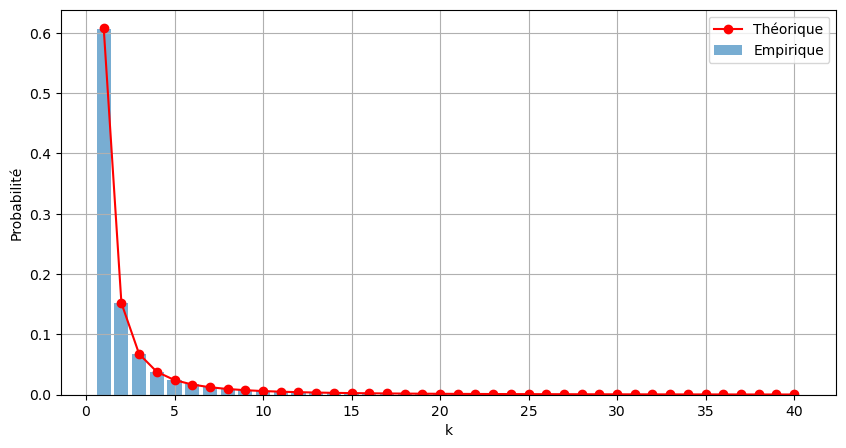

In [17]:
K=40
k=np.arange(1,K+1)
p_theo=6/(np.pi**2*k**2)
p_emp=np.array([(X==j).mean() for j in k])
plt.figure(figsize=(10,5))
plt.bar(k,p_emp,alpha=.6,label="Empirique")
plt.plot(k,p_theo,"r-o",label="Théorique")
plt.legend(); plt.grid(); plt.xlabel("k"); plt.ylabel("Probabilité"); plt.show()

## Comparaison cumulée

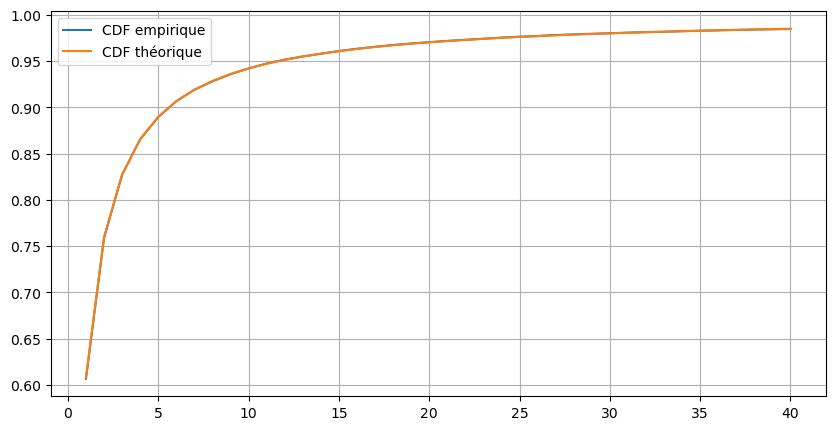

In [18]:
F_emp=np.cumsum(p_emp)
F_theo=np.cumsum(p_theo)
plt.figure(figsize=(10,5))
plt.plot(k,F_emp,label="CDF empirique")
plt.plot(k,F_theo,label="CDF théorique")
plt.legend(); plt.grid(); plt.show()

## Erreurs absolues

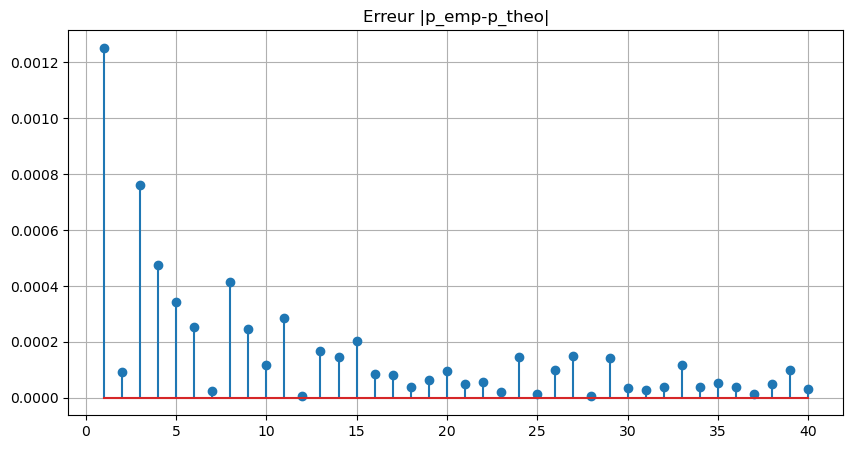

Erreur maximale= 0.0012521018540266882


In [19]:
err=np.abs(p_emp-p_theo)
plt.figure(figsize=(10,5))
plt.stem(k,err)
plt.grid()
plt.title("Erreur |p_emp-p_theo|")
plt.show()
print("Erreur maximale=",err.max())

## Tableau comparatif

In [8]:
print("k   empirique   theorique")
for j in range(1,16):
    print(f"{j:2d}  {(X==j).mean():.6f}  {6/(np.pi**2*j**2):.6f}")

k   empirique   theorique
 1  0.607460  0.607927
 2  0.152035  0.151982
 3  0.067350  0.067547
 4  0.038085  0.037995
 5  0.024030  0.024317
 6  0.017010  0.016887
 7  0.012610  0.012407
 8  0.009680  0.009499
 9  0.007220  0.007505
10  0.006460  0.006079
11  0.005135  0.005024
12  0.004140  0.004222
13  0.003795  0.003597
14  0.003295  0.003102
15  0.002455  0.002702
